# Obrasgov infrastructure locations

**Output:** `datasets/obrasgov/final.gpkg` (a verified local copy of the approved derivative). `map_components` contains retained points and lines. `excluded_primary_state` preserves components excluded because they lie entirely outside the project's reported primary state.

**Why:** A project can have several geometry components, and project IDs can repeat. We keep original records and planned-investment amounts, but screen components before using them on the map. This notebook runs the existing [snapshot translation](../../code/brazil_project/infrastructure/projects.py), [location QA](../../code/brazil_project/infrastructure/location_qa.py), [primary-state check](../../code/scripts/check_obras_primary_state.py) and [approved filter](../../code/scripts/filter_obras_primary_state.py).

In [1]:
DATASET = "obrasgov"
from pathlib import Path
import os, sys, sqlite3
from IPython.display import display
import pandas as pd
import matplotlib.pyplot as plt
PROJECT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / "project.toml").is_file())
sys.path[:0] = [str(PROJECT / "code"), str(PROJECT / "datasets"), str(PROJECT / "datasets" / DATASET)]
from processing import build, inspect_final
REBUILD = os.environ.get("BRAZIL_NOTEBOOK_REBUILD", "1") == "1"
print("Project:", PROJECT.name)
print("Mode:", "build from local inputs" if REBUILD else "preview existing verified local output")

Project: brazil-project
Mode: preview existing verified local output


## 1. Process and screen local records

The combined command runs snapshot translation → component-level location QA → screening figure → complete-geometry state check → approved exclusions. Polygons stay in the audit but are omitted from the map. A location partly inside or touching its primary state is retained under the baseline policy. No coordinates are corrected.

In [2]:
result = build(PROJECT) if REBUILD else inspect_final(PROJECT)
display(pd.DataFrame([{"retained point/line components": result["features"],
                       "excluded by primary state": result["excluded_primary_state"],
                       "CRS": f"EPSG:{result['epsg']}"}]))
print("Local GeoPackage:", Path(result["file"]).relative_to(PROJECT))
print("SHA-256:", result["sha256"])

,retained point/line components,excluded by primary state,CRS
0,224495,2346,EPSG:4674


Local GeoPackage: outputs/maps/obrasgov-primary-state-filter/locations.gpkg
SHA-256: 81c58321b8f8d7faf8d2fb078feddc4761358de47500c2747881db5036d5b0f6


## 2. Check the retained geometry

These counts are **location components**, not distinct projects or investments. Project amounts must not be summed over components.

In [3]:
with sqlite3.connect(f"file:{result['file']}?mode=ro", uri=True) as db:
    kinds = pd.read_sql_query('SELECT geometry_type, COUNT(*) AS components FROM map_components GROUP BY geometry_type ORDER BY components DESC', db)
kinds["type"] = kinds.geometry_type.map({"Point": "Points", "LineString": "Lines"}).fillna(kinds.geometry_type)
display(kinds[["type", "components"]].rename(columns={"components": "Location components"}))
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(kinds.type, kinds.components, color="#147d92")
ax.set_ylabel("Retained location components")
ax.set_title("Obrasgov map geometry")
fig.tight_layout()
display(fig)
plt.close(fig)

,type,Location components
0,Points,200643
1,Lines,23852


<Figure size 600x300 with 1 Axes>

## 3. Before and after, as a map

The illustration shows **points only**. Lines, polygons and already quarantined points are omitted; it is not a count of all projects.

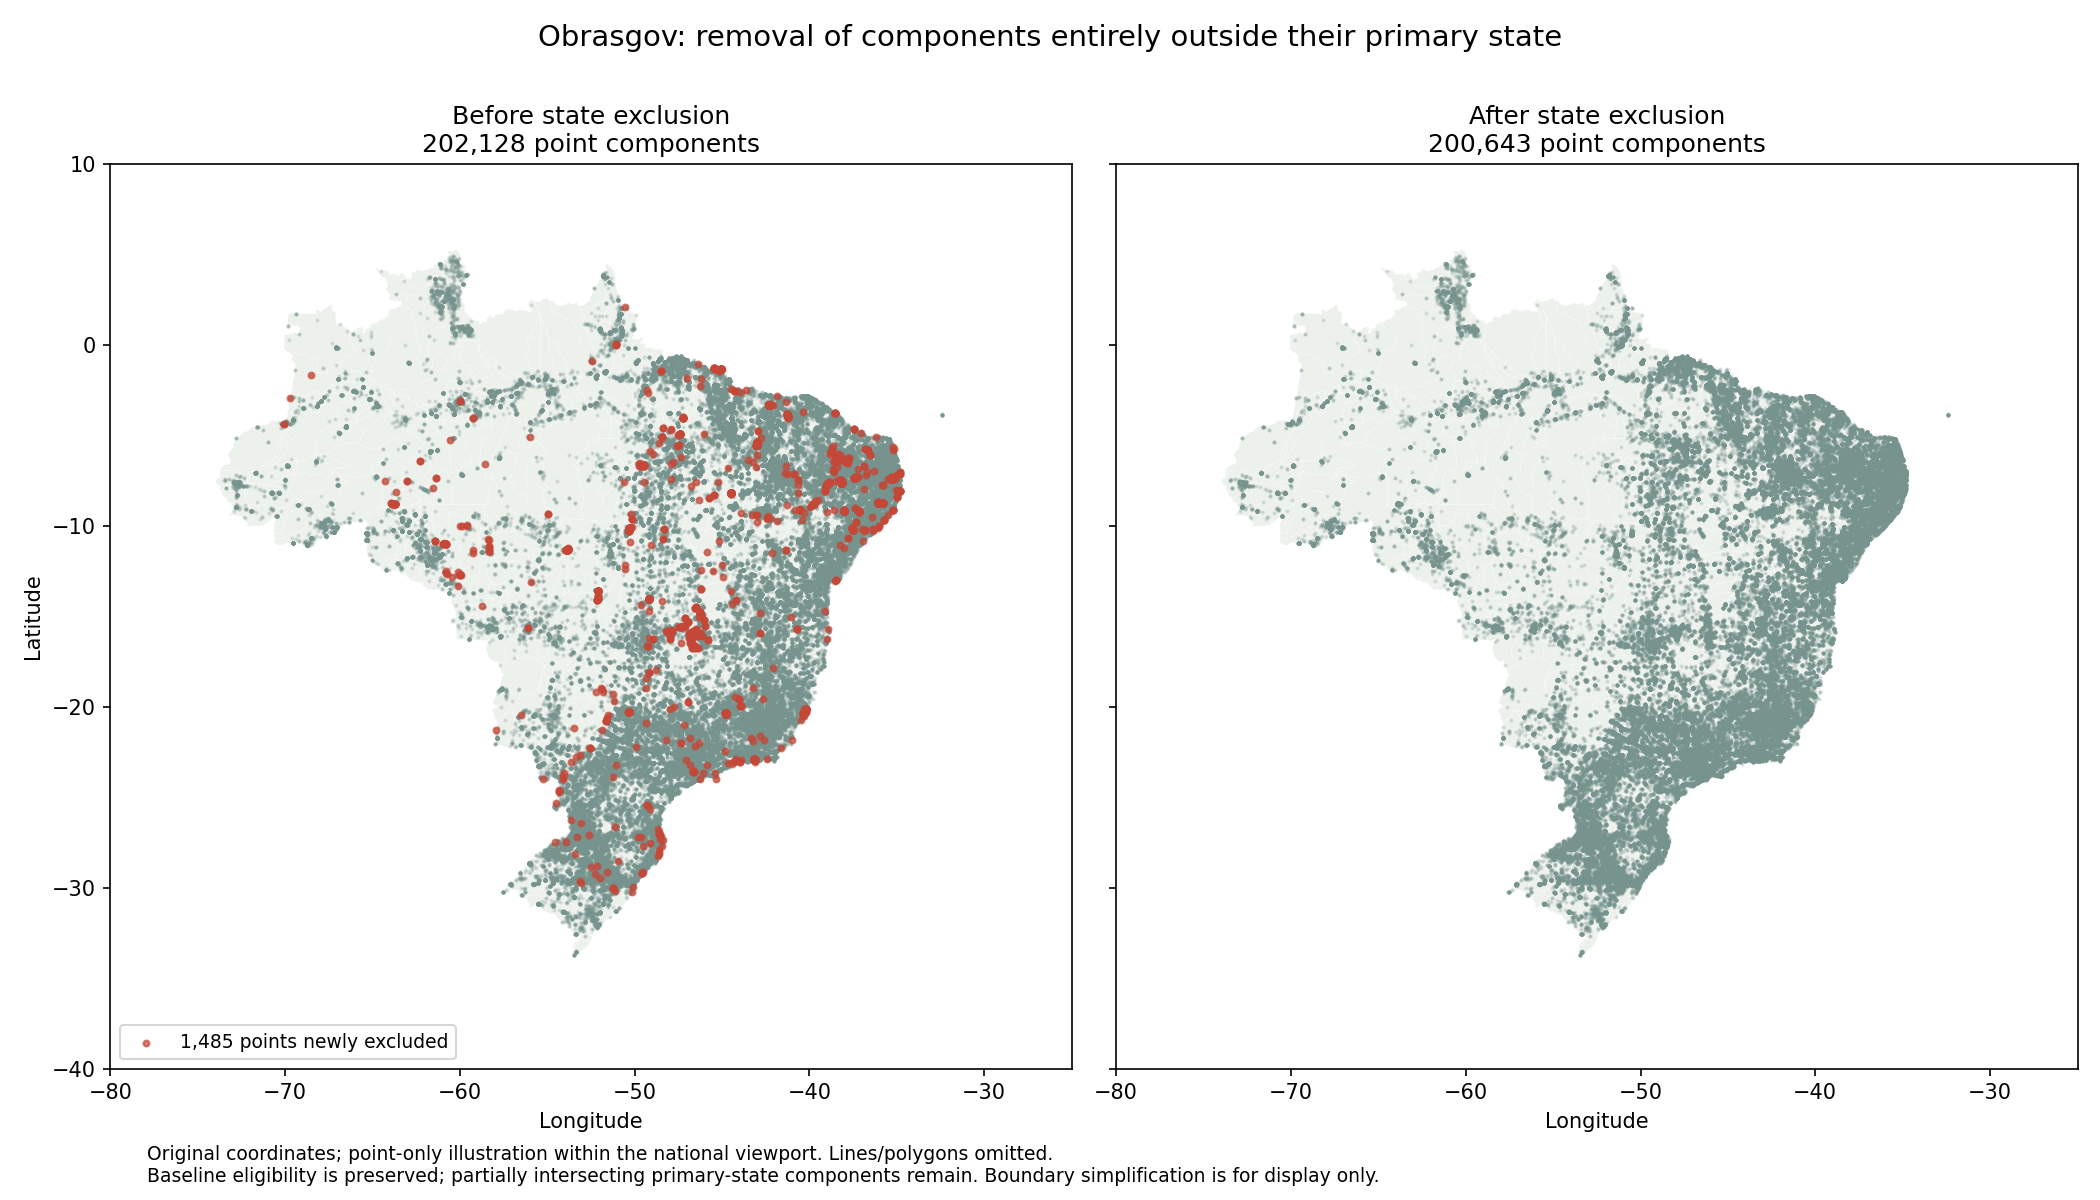

In [4]:
from IPython.display import Image
figure = PROJECT / "outputs/figures/obrasgov-location-qa/primary-state-filter.png"
if figure.is_file():
    display(Image(filename=str(figure)))
else:
    print("No saved comparison figure. Run the full pipeline to generate it.")

**Limit:** Retained coordinates are eligible for display, not independently verified locations. The reported primary state can be an incomplete description of a multi-state project. See the [location policy](../../docs/obrasgov-location-policy.md) and [exclusion audit](../../docs/obrasgov-primary-state-filter.md).